# Task 3: Unsupervised Learning and Clustering Analysis

**Internship:** Virtual Data Science with Python Trainee

**Platform:** YuvaIntern

**Objective:** To apply unsupervised learning techniques to segment customers into meaningful clusters based on their purchasing behaviour and analyze the characteristics of each cluster.

**Dataset:** Online Retail

**Source:** UCI Machine Learning Repository

**Algorithm:** K-Means Clustering

**Techniques:** RFM Analysis, Feature Scaling, Elbow Method, and Cluster Visualization

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Load the cleaned dataset
df = pd.read_csv("online_retail_cleaned.csv")

# Display the first five rows
display(df.head())

# Check dataset dimensions
print("Dataset Shape:", df.shape)

# Display column names
print("\nColumn Names:")
print(df.columns.tolist())

# Check data types and missing values
print("\nDataset Information:")
df.info()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,01-12-2010 08:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,01-12-2010 08:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,01-12-2010 08:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,01-12-2010 08:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,01-12-2010 08:26,3.39,17850.0,United Kingdom


Dataset Shape: (536641, 8)

Column Names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 536641 entries, 0 to 536640
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    536641 non-null  object 
 1   StockCode    536641 non-null  object 
 2   Description  535187 non-null  object 
 3   Quantity     536641 non-null  int64  
 4   InvoiceDate  536641 non-null  object 
 5   UnitPrice    536641 non-null  float64
 6   CustomerID   401604 non-null  float64
 7   Country      536641 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 32.8+ MB


In [3]:
# Create a copy of the dataset
data = df.copy()

# Convert InvoiceDate to datetime format
data["InvoiceDate"] = pd.to_datetime(data["InvoiceDate"], errors="coerce")

# Remove rows with missing CustomerID or InvoiceDate
data = data.dropna(subset=["CustomerID", "InvoiceDate"])

# Remove cancelled invoices
data = data[~data["InvoiceNo"].astype(str).str.startswith("C")]

# Keep valid positive quantities and prices
data = data[(data["Quantity"] > 0) & (data["UnitPrice"] > 0)]

# Create TotalSales column
data["TotalSales"] = data["Quantity"] * data["UnitPrice"]

# Display the results
print("Original dataset rows:", len(df))
print("Rows after data preparation:", len(data))
print("Unique customers:", data["CustomerID"].nunique())
print("Missing CustomerIDs:", data["CustomerID"].isna().sum())

display(data.head())

Original dataset rows: 536641
Rows after data preparation: 166363
Unique customers: 2997
Missing CustomerIDs: 0


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalSales
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-01-12 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-01-12 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-01-12 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-01-12 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-01-12 08:26:00,3.39,17850.0,United Kingdom,20.34


In [4]:
# Set the reference date as one day after the last invoice date
reference_date = data["InvoiceDate"].max() + pd.Timedelta(days=1)

# Calculate RFM metrics for each customer
rfm = data.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x: (reference_date - x.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("TotalSales", "sum")
)

# Display the first five customers
display(rfm.head())

# Display summary statistics
print("Total customers:", len(rfm))
print("\nRFM Summary:")
display(rfm.describe().round(2))

,Recency,Frequency,Monetary
CustomerID,,,
12347.0,96,5,2540.29
12348.0,221,1,367.00
12350.0,312,1,334.40
12352.0,275,3,1296.38
12355.0,97,1,459.40


Total customers: 2997

RFM Summary:


,Recency,Frequency,Monetary
count,2997.00,2997.00,2997.00
mean,155.39,2.66,1289.78
std,140.14,4.01,5273.01
min,1.00,1.00,5.90
25%,40.00,1.00,244.41
50%,125.00,2.00,466.29
75%,219.00,3.00,1064.28
max,698.00,106.00,168469.60


In [5]:
# Select RFM features
rfm_features = rfm[["Recency", "Frequency", "Monetary"]].copy()

# Apply StandardScaler
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_features)

# Convert scaled data into a DataFrame
rfm_scaled_df = pd.DataFrame(
    rfm_scaled,
    columns=["Recency", "Frequency", "Monetary"],
    index=rfm.index
)

# Display the scaled features
display(rfm_scaled_df.head())

print("Scaled data shape:", rfm_scaled_df.shape)
print("Feature scaling completed successfully!")

,Recency,Frequency,Monetary
CustomerID,,,
12347.0,-0.423848,0.584713,0.237193
12348.0,0.468278,-0.413228,-0.175029
12350.0,1.117745,-0.413228,-0.181213
12352.0,0.853676,0.085742,0.001252
12355.0,-0.416711,-0.413228,-0.157503


Scaled data shape: (2997, 3)
Feature scaling completed successfully!


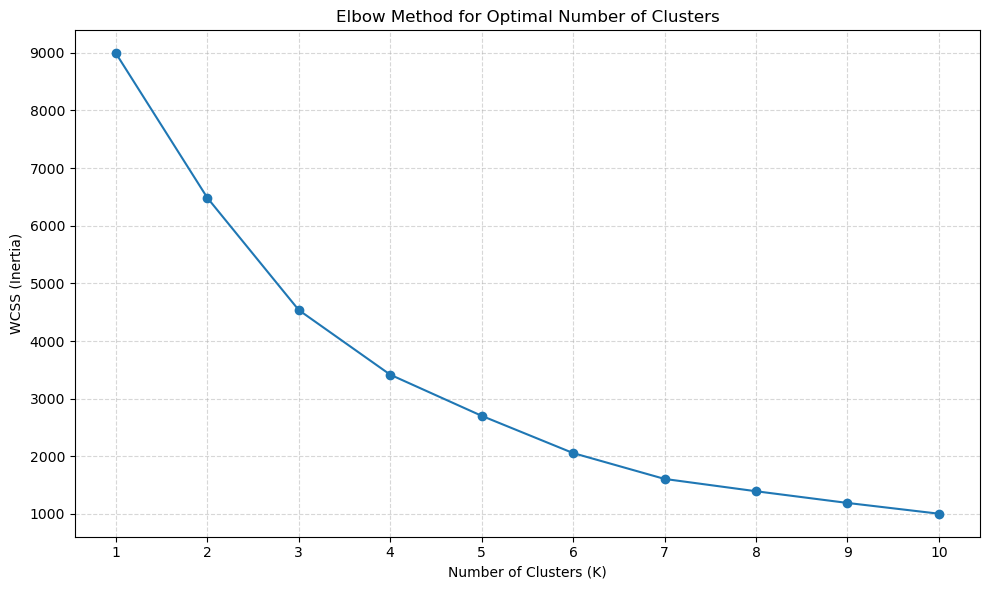

Elbow Method executed successfully!


In [7]:

# Step 1: Suppress the CPU core detection warning
import os
os.environ["LOKY_MAX_CPU_COUNT"] = "6"

import warnings
warnings.filterwarnings(
    "ignore",
    message="Could not find the number of physical cores.*",
    category=UserWarning
)

# Step 2: Import required libraries
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# Step 3: Calculate WCSS for different values of K
wcss = []

for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(rfm_scaled_df)
    wcss.append(kmeans.inertia_)

# Step 4: Plot the Elbow Method graph
plt.figure(figsize=(10, 6))
plt.plot(
    range(1, 11),
    wcss,
    marker="o",
    linestyle="-"
)

plt.title("Elbow Method for Optimal Number of Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS (Inertia)")
plt.xticks(range(1, 11))
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

print("Elbow Method executed successfully!")


In [8]:
# Set the number of clusters based on the Elbow Method
k = 3

# Apply K-Means clustering
kmeans = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=10
)

rfm["Cluster"] = kmeans.fit_predict(rfm_scaled_df)

# Display customers with their cluster labels
display(rfm.head(10))

# Count customers in each cluster
print("\nNumber of customers in each cluster:")
print(rfm["Cluster"].value_counts().sort_index())

print("\nK-Means clustering completed successfully!")

,Recency,Frequency,Monetary,Cluster
CustomerID,,,,
12347.0,96,5,2540.29,0
12348.0,221,1,367.00,1
12350.0,312,1,334.40,1
12352.0,275,3,1296.38,1
12355.0,97,1,459.40,0
12356.0,129,1,481.46,0
12357.0,183,1,6207.67,0
12358.0,4,2,1168.06,0
12359.0,10,3,3495.73,0



Number of customers in each cluster:
Cluster
0    1970
1    1013
2      14
Name: count, dtype: int64

K-Means clustering completed successfully!


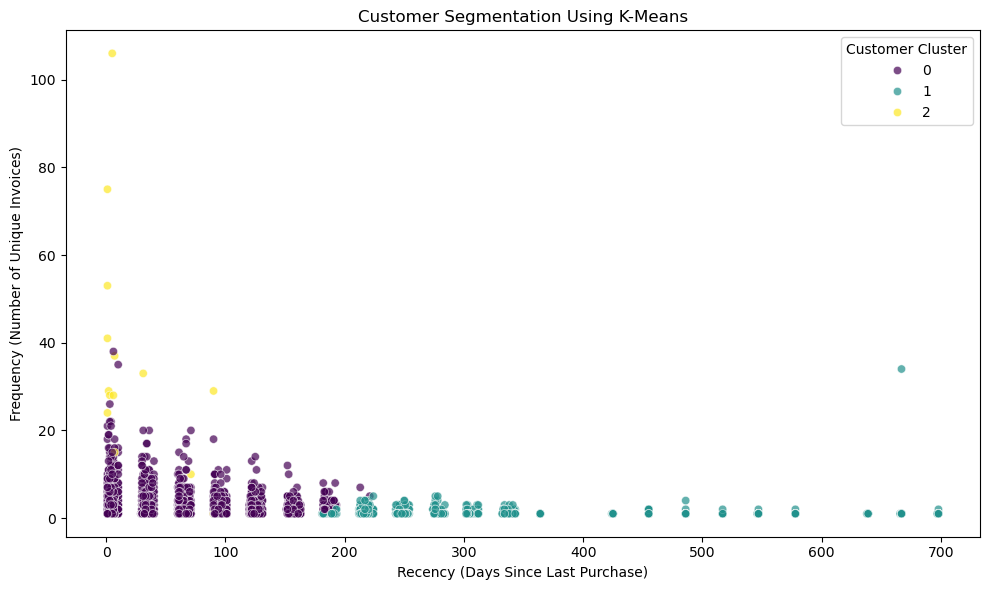

In [9]:

# Visualize customer clusters using Recency and Frequency

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=rfm.reset_index(),
    x="Recency",
    y="Frequency",
    hue="Cluster",
    palette="viridis",
    alpha=0.7
)

plt.title("Customer Segmentation Using K-Means")
plt.xlabel("Recency (Days Since Last Purchase)")
plt.ylabel("Frequency (Number of Unique Invoices)")
plt.legend(title="Customer Cluster")
plt.tight_layout()
plt.show()


In [10]:

# Calculate average RFM values for each cluster
cluster_summary = rfm.groupby("Cluster").agg(
    Customer_Count=("Recency", "count"),
    Average_Recency=("Recency", "mean"),
    Average_Frequency=("Frequency", "mean"),
    Average_Monetary=("Monetary", "mean")
).round(2)

# Display the cluster summary
display(cluster_summary)

# Calculate the percentage of customers in each cluster
cluster_summary["Customer_Percentage"] = (
    cluster_summary["Customer_Count"] / len(rfm) * 100
).round(2)

print("\nCluster Summary with Customer Percentages:")
display(cluster_summary)


,Customer_Count,Average_Recency,Average_Frequency,Average_Monetary
Cluster,,,,
0,1970,77.77,3.11,1341.91
1,1013,308.17,1.30,440.47
2,14,22.57,36.36,55407.06



Cluster Summary with Customer Percentages:


,Customer_Count,Average_Recency,Average_Frequency,Average_Monetary,Customer_Percentage
Cluster,,,,,
0,1970,77.77,3.11,1341.91,65.73
1,1013,308.17,1.30,440.47,33.80
2,14,22.57,36.36,55407.06,0.47


In [11]:

# Evaluate the clustering model using Silhouette Score

if rfm["Cluster"].nunique() > 1:
    score = silhouette_score(
        rfm_scaled_df,
        rfm["Cluster"]
    )

    print("Number of clusters:", rfm["Cluster"].nunique())
    print("Silhouette Score:", round(score, 4))
else:
    print("Silhouette Score cannot be calculated for a single cluster.")


Number of clusters: 3
Silhouette Score: 0.4432
